<a href="https://colab.research.google.com/github/0xkanagaraj/transformer-next-token-prediction/blob/main/transformer_next_token.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Transformer-Based Next-Token Prediction with Basic Self-Attention

A small decoder-only Transformer built **from scratch in PyTorch**. Self-attention (queries, keys, values, causal mask, softmax) is implemented by hand, not with `nn.MultiheadAttention`. The model is trained at character level to predict the next character.

## 1. Imports and setup

In [1]:
import math, urllib.request
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F

torch.manual_seed(42)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| device:", device)

PyTorch: 2.11.0+cu130 | device: cuda


## 2. Hyperparameters

In [2]:
batch_size = 64        # sequences per batch
block_size = 128       # context length (tokens the model can look back at)
n_embd = 128           # embedding dimension
n_head = 4             # attention heads per layer
n_layer = 4            # transformer blocks
dropout = 0.1
learning_rate = 3e-4
max_iters = 3000
eval_interval = 250
eval_iters = 100

## 3. Load the text data

The Tiny Shakespeare corpus (about 1 MB of text). If the download fails, a very small built-in passage is used so the notebook still runs (results will be much weaker).

In [3]:
url = "https://raw.githubusercontent.com/karpathy/char-rnn/master/data/tinyshakespeare/input.txt"
try:
    urllib.request.urlretrieve(url, "input.txt")
    text = open("input.txt", encoding="utf-8").read()
    print("Downloaded Tiny Shakespeare.")
except Exception as e:
    print("Download failed:", e)
    print("Using a tiny built-in fallback text instead.")
    fallback = ("To be, or not to be, that is the question: "
                "Whether 'tis nobler in the mind to suffer "
                "The slings and arrows of outrageous fortune, "
                "Or to take arms against a sea of troubles "
                "And by opposing end them. ")
    text = fallback * 200

print("Characters in corpus:", len(text))
print(text[:200])

Downloaded Tiny Shakespeare.
Characters in corpus: 1115394
First Citizen:
Before we proceed any further, hear me speak.

All:
Speak, speak.

First Citizen:
You are all resolved rather to die than to famish?

All:
Resolved. resolved.

First Citizen:
First, you


## 4. Character-level tokenizer and train/validation split

In [4]:
chars = sorted(set(text))
vocab_size = len(chars)
stoi = {ch: i for i, ch in enumerate(chars)}
itos = {i: ch for ch, i in stoi.items()}

encode = lambda s: [stoi[c] for c in s if c in stoi]
decode = lambda ids: "".join(itos[i] for i in ids)

data = torch.tensor(encode(text), dtype=torch.long)
n = int(0.9 * len(data))
train_data, val_data = data[:n], data[n:]
print("Vocab size:", vocab_size)
print("Train tokens:", len(train_data), "| Val tokens:", len(val_data))
print("Random-guess loss would be ln(vocab) =", round(math.log(vocab_size), 3))

def get_batch(split):
    d = train_data if split == "train" else val_data
    ix = torch.randint(len(d) - block_size - 1, (batch_size,))
    x = torch.stack([d[i:i + block_size] for i in ix])
    y = torch.stack([d[i + 1:i + block_size + 1] for i in ix])   # targets are inputs shifted by one
    return x.to(device), y.to(device)

Vocab size: 65
Train tokens: 1003854 | Val tokens: 111540
Random-guess loss would be ln(vocab) = 4.174


## 5. Build the model

**Self-attention head:** each token produces a query, key and value. Attention scores are `softmax(QKᵀ / √d)`, with a causal mask so a token can only look at earlier tokens. The output is the attention-weighted sum of the values.

In [5]:
class SelfAttentionHead(nn.Module):
    # One head of causal scaled dot-product self-attention
    def __init__(self, head_size):
        super().__init__()
        self.key = nn.Linear(n_embd, head_size, bias=False)
        self.query = nn.Linear(n_embd, head_size, bias=False)
        self.value = nn.Linear(n_embd, head_size, bias=False)
        self.register_buffer("tril", torch.tril(torch.ones(block_size, block_size)))
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        B, T, C = x.shape
        k = self.key(x)                                   # (B, T, head_size)
        q = self.query(x)                                 # (B, T, head_size)
        wei = q @ k.transpose(-2, -1) * k.size(-1) ** -0.5   # (B, T, T) scaled scores
        wei = wei.masked_fill(self.tril[:T, :T] == 0, float("-inf"))   # causal mask
        wei = F.softmax(wei, dim=-1)
        self.att = wei.detach()                           # saved for visualization
        wei = self.drop(wei)
        return wei @ self.value(x)                        # (B, T, head_size)


class MultiHeadAttention(nn.Module):
    def __init__(self, num_heads, head_size):
        super().__init__()
        self.heads = nn.ModuleList([SelfAttentionHead(head_size) for _ in range(num_heads)])
        self.proj = nn.Linear(num_heads * head_size, n_embd)
        self.drop = nn.Dropout(dropout)

    def forward(self, x):
        out = torch.cat([h(x) for h in self.heads], dim=-1)
        return self.drop(self.proj(out))


class FeedForward(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(n_embd, 4 * n_embd), nn.ReLU(),
            nn.Linear(4 * n_embd, n_embd), nn.Dropout(dropout))

    def forward(self, x):
        return self.net(x)


class Block(nn.Module):
    # Transformer block: attention + feed-forward, with residual connections and layer norm
    def __init__(self):
        super().__init__()
        self.sa = MultiHeadAttention(n_head, n_embd // n_head)
        self.ffwd = FeedForward()
        self.ln1 = nn.LayerNorm(n_embd)
        self.ln2 = nn.LayerNorm(n_embd)

    def forward(self, x):
        x = x + self.sa(self.ln1(x))
        x = x + self.ffwd(self.ln2(x))
        return x


class TransformerLM(nn.Module):
    def __init__(self):
        super().__init__()
        self.tok_emb = nn.Embedding(vocab_size, n_embd)
        self.pos_emb = nn.Embedding(block_size, n_embd)
        self.blocks = nn.Sequential(*[Block() for _ in range(n_layer)])
        self.ln_f = nn.LayerNorm(n_embd)
        self.lm_head = nn.Linear(n_embd, vocab_size)
        self.apply(self._init_weights)

    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
        elif isinstance(m, nn.Embedding):
            nn.init.normal_(m.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.shape
        x = self.tok_emb(idx) + self.pos_emb(torch.arange(T, device=idx.device))
        x = self.blocks(x)
        logits = self.lm_head(self.ln_f(x))               # (B, T, vocab_size)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, vocab_size), targets.view(-1))
        return logits, loss

    @torch.no_grad()
    def generate(self, idx, max_new_tokens, temperature=1.0, top_k=None):
        for _ in range(max_new_tokens):
            logits, _ = self(idx[:, -block_size:])
            logits = logits[:, -1, :] / temperature
            if top_k is not None:
                v, _ = torch.topk(logits, top_k)
                logits[logits < v[:, [-1]]] = float("-inf")
            probs = F.softmax(logits, dim=-1)
            idx = torch.cat([idx, torch.multinomial(probs, 1)], dim=1)
        return idx


model = TransformerLM().to(device)
print(f"Parameters: {sum(p.numel() for p in model.parameters()) / 1e6:.2f} M")

Parameters: 0.82 M


## 6. Train

In [6]:
@torch.no_grad()
def estimate_loss():
    model.eval()
    out = {}
    for split in ["train", "val"]:
        losses = torch.zeros(eval_iters)
        for k in range(eval_iters):
            xb, yb = get_batch(split)
            _, loss = model(xb, yb)
            losses[k] = loss.item()
        out[split] = losses.mean().item()
    model.train()
    return out

optimizer = torch.optim.AdamW(model.parameters(), lr=learning_rate)
steps, train_losses, val_losses = [], [], []

for it in range(max_iters + 1):
    if it % eval_interval == 0:
        l = estimate_loss()
        steps.append(it); train_losses.append(l["train"]); val_losses.append(l["val"])
        print(f"step {it:5d} | train loss {l['train']:.4f} | val loss {l['val']:.4f}")
    xb, yb = get_batch("train")
    _, loss = model(xb, yb)
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    optimizer.step()

step     0 | train loss 4.2165 | val loss 4.2190
step   250 | train loss 2.3916 | val loss 2.4056
step   500 | train loss 2.0717 | val loss 2.1234
step   750 | train loss 1.8248 | val loss 1.9411
step  1000 | train loss 1.6817 | val loss 1.8305
step  1250 | train loss 1.5995 | val loss 1.7739
step  1500 | train loss 1.5395 | val loss 1.7255
step  1750 | train loss 1.4968 | val loss 1.6855
step  2000 | train loss 1.4634 | val loss 1.6654
step  2250 | train loss 1.4338 | val loss 1.6409
step  2500 | train loss 1.4170 | val loss 1.6310
step  2750 | train loss 1.3951 | val loss 1.6056
step  3000 | train loss 1.3765 | val loss 1.5986


## 7. Loss curves and perplexity

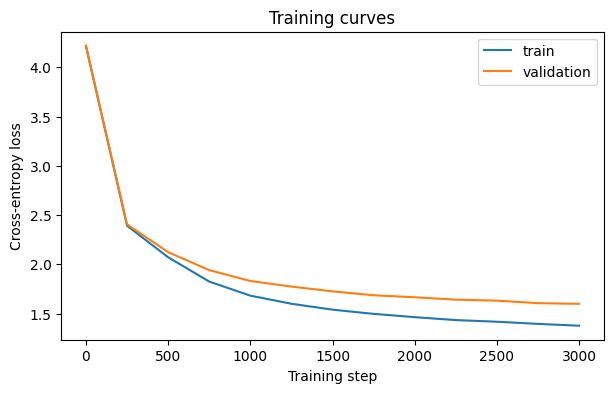

Final validation loss: 1.5986
Validation perplexity: 4.95  (random guessing = 65)


In [7]:
plt.figure(figsize=(7, 4))
plt.plot(steps, train_losses, label="train")
plt.plot(steps, val_losses, label="validation")
plt.xlabel("Training step"); plt.ylabel("Cross-entropy loss")
plt.title("Training curves"); plt.legend(); plt.show()

print(f"Final validation loss: {val_losses[-1]:.4f}")
print(f"Validation perplexity: {math.exp(val_losses[-1]):.2f}  (random guessing = {vocab_size})")

## 8. Next-token accuracy on validation data

In [8]:
model.eval()
correct = total = 0
with torch.no_grad():
    for _ in range(50):
        xb, yb = get_batch("val")
        logits, _ = model(xb)
        pred = logits.argmax(dim=-1)
        correct += (pred == yb).sum().item()
        total += yb.numel()
print(f"Next-token (top-1) accuracy: {correct / total:.2%}")

Next-token (top-1) accuracy: 52.66%


## 9. Top-5 next-token predictions for a prompt

In [9]:
def top_next_tokens(prompt, k=5):
    ids = encode(prompt)
    x = torch.tensor([ids[-block_size:]], device=device)
    model.eval()
    with torch.no_grad():
        logits, _ = model(x)
    probs = F.softmax(logits[0, -1], dim=-1)
    top = torch.topk(probs, k)
    print(f"Prompt: {prompt!r}")
    for p, i in zip(top.values, top.indices):
        print(f"  {itos[i.item()]!r:8} {p.item():.2%}")

top_next_tokens("To be, or not to b")
top_next_tokens("The quick brown fo")

Prompt: 'To be, or not to b'
  'e'      75.85%
  'r'      4.35%
  'a'      4.22%
  'l'      3.97%
  'u'      3.44%
Prompt: 'The quick brown fo'
  'r'      85.98%
  'l'      4.88%
  'o'      4.77%
  'u'      2.44%
  'e'      1.16%


## 10. Generate text

In [10]:
def generate_text(prompt="", max_new_tokens=400, temperature=0.8, top_k=40):
    ids = encode(prompt)
    idx = torch.tensor([ids] if ids else [[0]], dtype=torch.long, device=device)
    model.eval()
    out = model.generate(idx, max_new_tokens, temperature=temperature, top_k=top_k)
    return decode(out[0].tolist())

print(generate_text("ROMEO:", temperature=0.8))

ROMEO:
Valinio's point upon so dance?

ROMEO:
I am leave not.

LUCIO:
The deeds is well: sir, I am duck, if we have love!

PAULINA:
For I see, sir, I play you hear may as viside.

Second Murderer:
Our counself.

CLARENCE:
My very mine of war, lads to make and fool'd wounds
And to his depart, I did.

GLOUCESTER:
You speak; no? where have poor in this corning.

CLIFFORD:
For ever I would note execute me w


## 11. Visualize the attention weights

Each row shows where a token looks. The causal mask makes the upper triangle zero, since tokens cannot see the future.

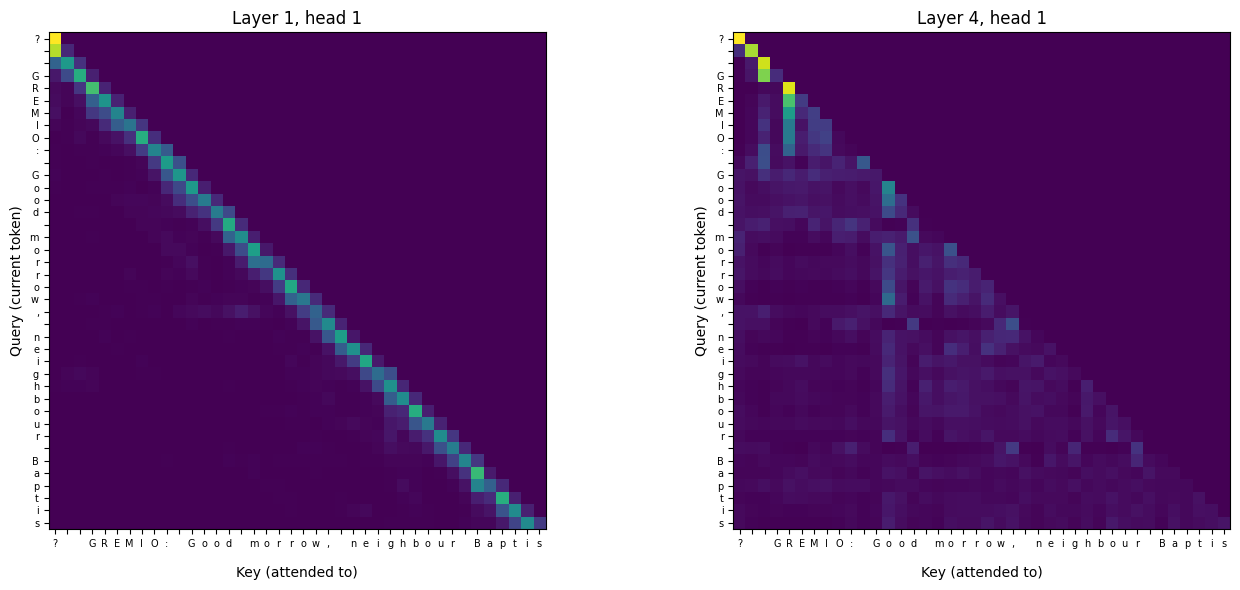

In [11]:
sample = decode(val_data[:40].tolist())
x = torch.tensor([encode(sample)], device=device)
model.eval()
with torch.no_grad():
    model(x)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
for ax, (layer, head) in zip(axes, [(0, 0), (n_layer - 1, 0)]):
    att = model.blocks[layer].sa.heads[head].att[0].cpu().numpy()
    ax.imshow(att, cmap="viridis")
    ax.set_xticks(range(len(sample))); ax.set_xticklabels(list(sample), fontsize=7)
    ax.set_yticks(range(len(sample))); ax.set_yticklabels(list(sample), fontsize=7)
    ax.set_title(f"Layer {layer + 1}, head {head + 1}")
    ax.set_xlabel("Key (attended to)"); ax.set_ylabel("Query (current token)")
plt.tight_layout(); plt.show()

## 12. Save the model

In [12]:
torch.save(model.state_dict(), "transformer_lm.pt")
print("Saved to transformer_lm.pt")

Saved to transformer_lm.pt
